<class 'pandas.DataFrame'>
Index: 4008 entries, 2022-01-03 to 2025-12-30
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Open          4008 non-null   float64
 1   High          4008 non-null   float64
 2   Low           4008 non-null   float64
 3   Close         4008 non-null   float64
 4   Volume        4008 non-null   int64  
 5   Dividends     4008 non-null   float64
 6   Stock Splits  4008 non-null   float64
 7   Ticker        4008 non-null   str    
dtypes: float64(6), int64(1), str(1)
memory usage: 281.8+ KB
Ticker
GILD    0
TDY     0
TROW    0
TSCO    0
Name: Difference, dtype: int64
TDY
Second highest gain: 2025-01-22
Second highest loss: 2025-04-04

GILD
Second highest gain: 2024-06-20
Second highest loss: 2025-05-06

TSCO
Second highest gain: 2023-01-26
Second highest loss: 2022-02-22

TROW
Second highest gain: 2025-04-09
Second highest loss: 2022-09-13

Index type: <class 'pandas.Index'>
Index name: 

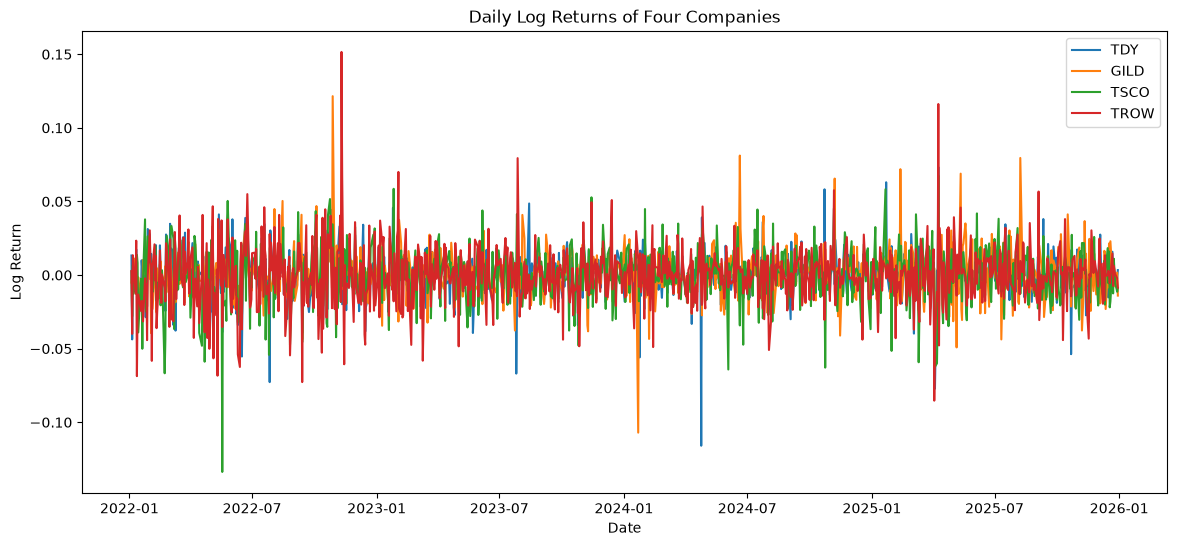

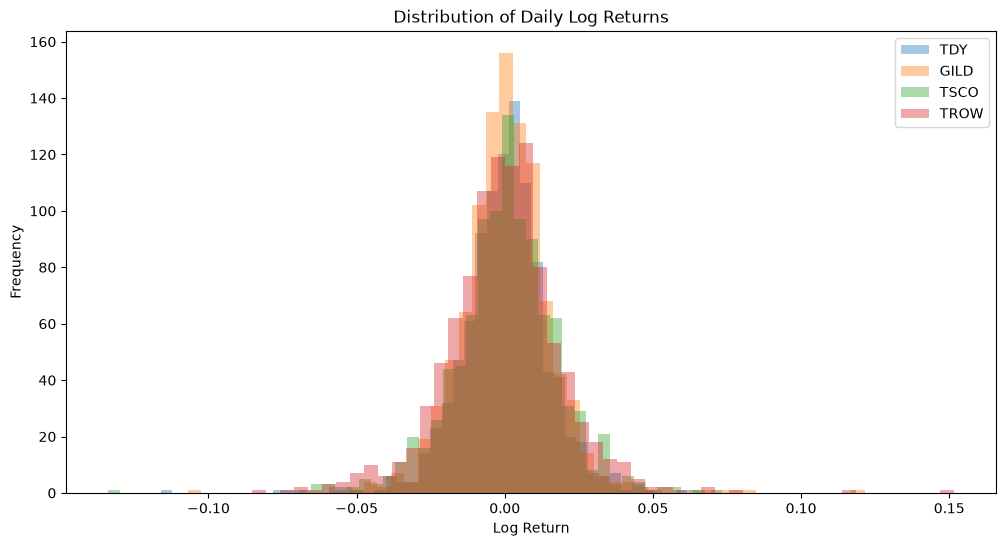

In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

TDY = pd.read_csv('Data-Processing-in-Python/midterm/TDY.csv')
GILD = pd.read_csv('Data-Processing-in-Python/midterm/GILD.csv')
TSCO = pd.read_csv('Data-Processing-in-Python/midterm/TSCO.csv')
TROW = pd.read_csv('Data-Processing-in-Python/midterm/TROW.csv')

TDY['Ticker'] = 'TDY'
GILD['Ticker'] = 'GILD'
TSCO['Ticker'] = 'TSCO'
TROW['Ticker'] = 'TROW'

data = pd.concat([TDY, GILD, TSCO, TROW])
data = data.set_index('Date')
data.head()
data.info()

data['Difference'] = data['High'] - data['Low']
print((data['Difference'] == 0).groupby(data['Ticker']).sum())

data.groupby('Ticker').agg({
    'High': 'max',
    'Low': 'min'
})

data['Log_Return'] = data.groupby('Ticker')['Close'].transform(
    lambda x: np.log(x / x.shift(1))
)

data.groupby('Ticker')['Log_Return'].agg([
    'min',
    'max',
    'mean',
    'std',
    'skew'
])

for ticker in data['Ticker'].unique():

    returns = data[data['Ticker'] == ticker]['Log_Return'].dropna()

    second_highest_gain = returns.drop(returns.idxmax()).idxmax()
    second_highest_loss = returns.drop(returns.idxmin()).idxmin()

    print(ticker)
    print('Second highest gain:', second_highest_gain)
    print('Second highest loss:', second_highest_loss)
    print()

print("Index type:", type(data.index))
print("Index name:", data.index.name)
print("Columns:", data.columns.tolist())
print(data.head())
data = data.reset_index()

data['Date'] = pd.to_datetime(data['Date'])
data = data.set_index('Date')

weekly = data.groupby('Ticker')['Volume'].resample('W').sum()

median_weekly_volume = weekly.groupby('Ticker').median()

median_weekly_volume

total_returns = data.groupby('Ticker')['Log_Return'].sum()

total_returns
total_returns.idxmin()

data['volume_class'] = ''
for ticker in data['Ticker'].unique():

    company = data[data['Ticker'] == ticker]

    low = company['Volume'].quantile(1/3)
    high = company['Volume'].quantile(2/3)

    data.loc[(data['Ticker'] == ticker) & (data['Volume'] <= low), 'volume_class'] = 'Low'

    data.loc[(data['Ticker'] == ticker) & (data['Volume'] > low) & (data['Volume'] <= high), 'volume_class'] = 'Medium'

    data.loc[(data['Ticker'] == ticker) & (data['Volume'] > high), 'volume_class'] = 'High'

data.groupby(['Ticker', 'volume_class']).size()

plt.figure(figsize=(14, 6))

for ticker in data['Ticker'].unique():
    company = data[data['Ticker'] == ticker]
    plt.plot(company.index, company['Log_Return'], label=ticker)

plt.title('Daily Log Returns of Four Companies')
plt.xlabel('Date')
plt.ylabel('Log Return')
plt.legend()
plt.show()

plt.figure(figsize=(12, 6))

for ticker in data['Ticker'].unique():
    company = data[data['Ticker'] == ticker]
    plt.hist(company['Log_Return'].dropna(), bins=50, alpha=0.4, label=ticker)

plt.title('Distribution of Daily Log Returns')
plt.xlabel('Log Return')
plt.ylabel('Frequency')
plt.legend()
plt.show()



Normal: 481
Uniform: 462
Exponential: 221
Binomial: 331


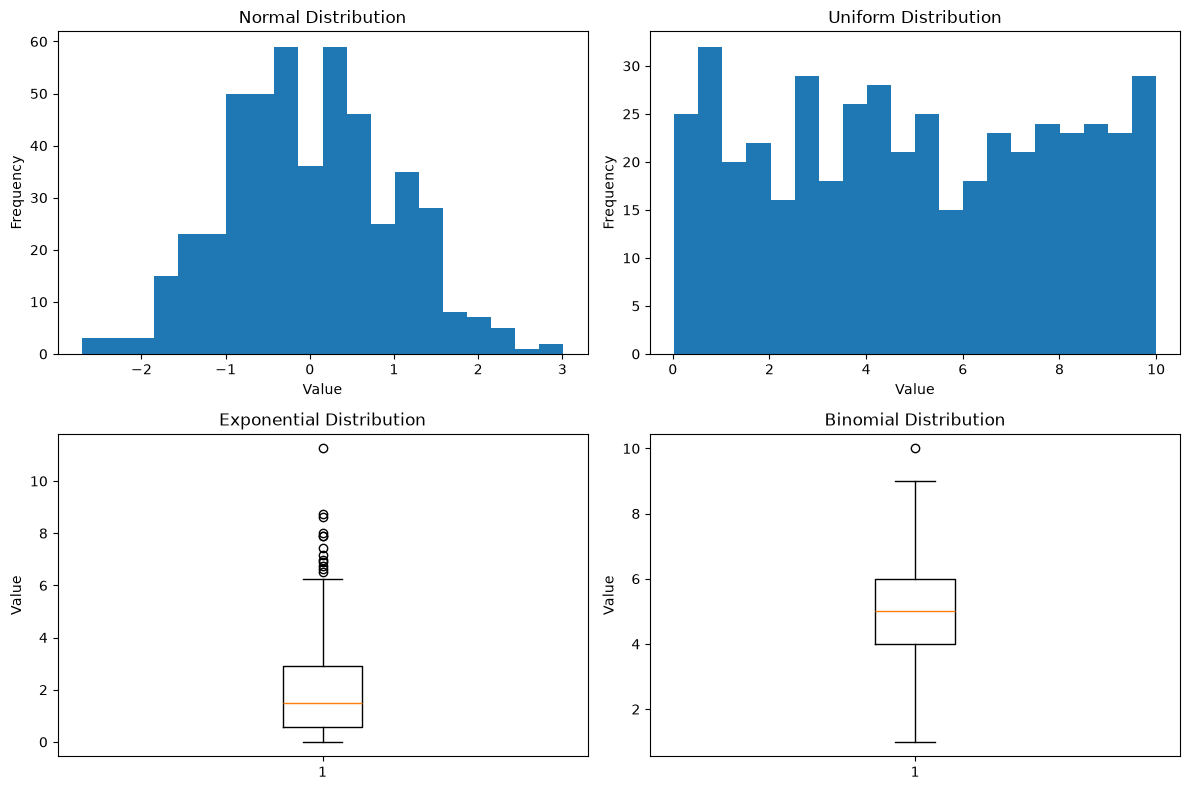

In [45]:

# PART 3

import numpy as np
import matplotlib.pyplot as plt


# TASK 1: Generate four random variables

# Random number of observations between 100 and 500
n1 = np.random.randint(100, 501)
n2 = np.random.randint(100, 501)
n3 = np.random.randint(100, 501)
n4 = np.random.randint(100, 501)

# Four different distributions
normal = np.random.normal(0, 1, n1)

uniform = np.random.uniform(0, 10, n2)

exponential = np.random.exponential(2, n3)

binomial = np.random.binomial(10, 0.5, n4)


# Check the number of observations
print('Normal:', len(normal))
print('Uniform:', len(uniform))
print('Exponential:', len(exponential))
print('Binomial:', len(binomial))


# TASK 2: Create a 2x2 grid of plots

plt.figure(figsize=(12, 8))

# Plot 1: Normal distribution - histogram
plt.subplot(2, 2, 1)
plt.hist(normal, bins=20)
plt.title('Normal Distribution')
plt.xlabel('Value')
plt.ylabel('Frequency')

# Plot 2: Uniform distribution - histogram
plt.subplot(2, 2, 2)
plt.hist(uniform, bins=20)
plt.title('Uniform Distribution')
plt.xlabel('Value')
plt.ylabel('Frequency')

# Plot 3: Exponential distribution - boxplot
plt.subplot(2, 2, 3)
plt.boxplot(exponential)
plt.title('Exponential Distribution')
plt.ylabel('Value')

# Plot 4: Binomial distribution - boxplot
plt.subplot(2, 2, 4)
plt.boxplot(binomial)
plt.title('Binomial Distribution')
plt.ylabel('Value')

plt.tight_layout()
plt.show()
